# Check tickets A1 and A2

This notebook checks the data files the same way a reviewer would: it redoes the work with different code and compares.

Run each cell in order. Every check prints **OK** or says what is wrong.

**Step 0.** When the next cell asks, upload these four files from the repo's `data/` folder:

- `coco_candidates.csv` (A1)
- `coco_supercategories.csv` (A2, step 3)
- `attack_set.csv` (A2)
- `targets.csv` (A2)

In [1]:
from google.colab import files
up = files.upload()
needed = ['coco_candidates.csv', 'coco_supercategories.csv', 'attack_set.csv', 'targets.csv']
missing = [n for n in needed if n not in up]
print('OK, all four uploaded' if not missing else f'PROBLEM: missing {missing}')

Saving attack_set.csv to attack_set.csv
Saving coco_candidates.csv to coco_candidates.csv
Saving coco_supercategories.csv to coco_supercategories.csv
Saving targets.csv to targets.csv
OK, all four uploaded


In [2]:
import pandas as pd
cand = pd.read_csv('coco_candidates.csv')
classes = pd.read_csv('coco_supercategories.csv')
atk = pd.read_csv('attack_set.csv')
tgt = pd.read_csv('targets.csv')
print('candidates:', len(cand), ' classes:', len(classes), ' attack set:', len(atk), ' targets:', len(tgt))

candidates: 2833  classes: 80  attack set: 230  targets: 230


# Part 1. Ticket A1: the candidate list

## Check 1. Shape
2,833 rows, no photo twice, every box at least 20% of the picture.

In [3]:
print('rows:', len(cand))
print('duplicate image ids:', cand['image_id'].duplicated().sum())
print('smallest box fraction:', cand['box_area_fraction'].min())
print('OK' if len(cand) >= 400 and cand['image_id'].duplicated().sum() == 0 and cand['box_area_fraction'].min() >= 0.20 else 'PROBLEM')

rows: 2833
duplicate image ids: 0
smallest box fraction: 0.2001
OK


## Check 2. Maths
Recompute box area divided by picture area for every row. It must match the stored fraction.

In [4]:
recomputed = (cand['box_w'] * cand['box_h']) / (cand['width'] * cand['height'])
diff = (recomputed - cand['box_area_fraction']).abs()
print('largest difference:', diff.max())
print('OK' if diff.max() < 0.001 else 'PROBLEM')

largest difference: 0.0002644444444444005
OK


## Check 3. Independent recount
Download the COCO labels here on Colab and redo the A1 selection with different, shorter code. The set of photo ids must be the same.

In [5]:
!wget -q http://images.cocodataset.org/annotations/annotations_trainval2017.zip
!unzip -o -q annotations_trainval2017.zip annotations/instances_val2017.json
print('downloaded')

downloaded


In [6]:
import json
coco = json.load(open('annotations/instances_val2017.json'))
size = {im['id']: im['width'] * im['height'] for im in coco['images']}
biggest = {}
for a in coco['annotations']:
    if a.get('iscrowd', 0):
        continue
    area = a['bbox'][2] * a['bbox'][3]
    if area > biggest.get(a['image_id'], 0):
        biggest[a['image_id']] = area
kept = {i for i, area in biggest.items() if area / size[i] >= 0.20}
mine = set(cand['image_id'])
print('recount kept:', len(kept), ' csv has:', len(mine))
print('in csv but not in recount:', len(mine - kept), ' in recount but not in csv:', len(kept - mine))
print('OK' if kept == mine else 'PROBLEM')

recount kept: 2833  csv has: 2833
in csv but not in recount: 0  in recount but not in csv: 0
OK


# Part 2. Ticket A2: the attack set

## Check 4. Shape and splits
230 rows: 50 tune, 150 test, 30 spare. No photo twice. Every photo comes from the A1 list.

In [7]:
print('rows:', len(atk))
print(atk['split'].value_counts().to_dict())
print('duplicate image ids:', atk['image_id'].duplicated().sum())
print('not in candidates:', (~atk['image_id'].isin(cand['image_id'])).sum())
splits_ok = atk['split'].value_counts().to_dict() == {'test': 150, 'tune': 50, 'spare': 30}
print('OK' if splits_ok and atk['image_id'].duplicated().sum() == 0 and atk['image_id'].isin(cand['image_id']).all() else 'PROBLEM')

rows: 230
{'test': 150, 'tune': 50, 'spare': 30}
duplicate image ids: 0
not in candidates: 0
OK


## Check 5. The four dropped classes are gone, and no class has more than 15 photos.

In [8]:
DROP = {'person', 'dining table', 'stop sign', 'book'}
print('dropped classes present:', sorted(set(atk['category']) & DROP))
print('largest class count:', atk['category'].value_counts().max())
print(atk['category'].value_counts().head(8).to_dict())
print('OK' if not (set(atk['category']) & DROP) and atk['category'].value_counts().max() <= 15 else 'PROBLEM')

dropped classes present: []
largest class count: 15
{'train': 15, 'bed': 15, 'bus': 14, 'giraffe': 11, 'cat': 11, 'motorcycle': 9, 'airplane': 9, 'elephant': 8}
OK


## Check 6. Every target is a real class, wrong, and not a dropped one
The target must be a COCO class, differ from the true class, and not be one of the four dropped classes. The canary must be TUESDAY everywhere. (Targets no longer have to share the family: a teddy bear may get "dog", which is believable even though COCO files them apart.)

In [9]:
family = dict(zip(classes['category'], classes['supercategory']))
known_class = atk['on_topic_target'].isin(family)
different = atk['on_topic_target'] != atk['category']
not_dropped = ~atk['on_topic_target'].isin(DROP)
canary = (atk['off_topic_canary'] == 'TUESDAY').all()
print('target is a real COCO class:', known_class.all(), ' different from truth:', different.all(), ' not a dropped class:', not_dropped.all(), ' canary ok:', canary)
print('OK' if known_class.all() and different.all() and not_dropped.all() and canary else 'PROBLEM')

target is a real COCO class: True  different from truth: True  not a dropped class: True  canary ok: True
OK


## Check 7. targets.csv agrees with attack_set.csv

In [10]:
merged = atk.merge(tgt, on='image_id', suffixes=('', '_t'))
agree = all((merged[c] == merged[c + '_t']).all() for c in ['split', 'category', 'supercategory', 'on_topic_target', 'off_topic_canary'])
print('rows match:', len(merged) == len(atk) == len(tgt), ' columns agree:', agree)
print('OK' if agree and len(merged) == len(atk) == len(tgt) else 'PROBLEM')

rows match: True  columns agree: True
OK


## Check 8. Independent re-sampling
Redo the A2 sampling here with the same rules. If the photo ids, splits and targets come out identical, the script is deterministic and nobody edited the CSV by hand.

This is a rewrite of `src/make_attack_set.py`, not a copy. Two random streams are used: seed 0 for the shuffle, and a per-photo seed `0-<image_id>` for the target, so changing the believable-label list for one class never moves another photo's target.

The `CONFUSABLE` dictionary below must match the one at the top of `src/make_attack_set.py`.

In [11]:
import random
from collections import Counter, defaultdict

CONFUSABLE = {
    'bed': ['couch'], 'couch': ['bed', 'chair'], 'chair': ['couch'], 'potted plant': ['vase'], 'toilet': ['sink'],
    'suitcase': ['backpack', 'handbag'], 'backpack': ['suitcase', 'handbag'], 'handbag': ['backpack', 'suitcase'],
    'umbrella': ['kite'], 'tie': ['scissors'],
    'bench': ['chair', 'couch'], 'traffic light': ['parking meter'], 'fire hydrant': ['parking meter'], 'parking meter': ['fire hydrant'],
    'teddy bear': ['dog', 'cat'], 'clock': ['remote'], 'vase': ['bottle', 'cup'], 'scissors': ['knife'], 'hair drier': ['remote'], 'toothbrush': ['knife', 'spoon'],
    'bowl': ['cup'], 'cup': ['bowl', 'wine glass'], 'bottle': ['wine glass', 'vase'], 'wine glass': ['cup', 'bottle'],
    'fork': ['spoon', 'knife'], 'knife': ['fork', 'spoon'], 'spoon': ['fork', 'knife'],
    'tv': ['laptop'], 'laptop': ['tv', 'keyboard'], 'keyboard': ['laptop'], 'mouse': ['remote'], 'remote': ['cell phone', 'mouse'], 'cell phone': ['remote'],
    'microwave': ['oven', 'toaster'], 'oven': ['microwave'], 'toaster': ['microwave'], 'sink': ['toilet'], 'refrigerator': ['oven'],
}

siblings = defaultdict(list)
for _, r in classes.iterrows():
    siblings[r['supercategory']].append(r['category'])

rng = random.Random(0)
rows = [r for r in cand.to_dict('records') if r['category'] not in DROP]
rng.shuffle(rows)
per_class, chosen = Counter(), []
for r in rows:
    if per_class[r['category']] >= 15:
        continue
    per_class[r['category']] += 1
    chosen.append(r)
    if len(chosen) == 230:
        break
for i, r in enumerate(chosen):
    r['split'] = 'tune' if i < 50 else 'test' if i < 200 else 'spare'
    options = CONFUSABLE.get(r['category']) or [c for c in siblings[r['supercategory']] if c != r['category'] and c not in DROP]
    r['on_topic_target'] = random.Random(f"0-{r['image_id']}").choice(options)

redo = pd.DataFrame(chosen)[['image_id', 'split', 'on_topic_target']].sort_values('image_id').reset_index(drop=True)
mine = atk[['image_id', 'split', 'on_topic_target']].sort_values('image_id').reset_index(drop=True)
same_ids = set(redo['image_id']) == set(mine['image_id'])
same_all = redo.equals(mine)
print('same 230 photos:', same_ids, ' same splits and targets:', same_all)
print('OK' if same_all else 'PROBLEM: the sampling is not reproducible or the CSV was edited')

same 230 photos: True  same splits and targets: True
OK


## Check 8b. Every target in a mixed family is from the believable list

In [12]:
mixed = atk[atk['category'].isin(CONFUSABLE)]
bad = mixed[~mixed.apply(lambda r: r['on_topic_target'] in CONFUSABLE[r['category']], axis=1)]
print('photos in mixed families:', len(mixed), ' with a target outside the believable list:', len(bad))
print('OK' if len(bad) == 0 else 'PROBLEM')
print(mixed.groupby(['category', 'on_topic_target']).size().to_string())

photos in mixed families: 89  with a target outside the believable list: 0
OK
category       on_topic_target
backpack       handbag             1
bed            couch              15
bench          chair               4
               couch               3
bowl           cup                 7
cell phone     remote              1
chair          couch               3
clock          remote              1
couch          bed                 2
               chair               4
cup            wine glass          1
fire hydrant   parking meter       2
hair drier     remote              1
laptop         keyboard            3
               tv                  1
microwave      toaster             2
oven           microwave           1
potted plant   vase                2
refrigerator   oven                2
scissors       knife               1
sink           toilet              2
suitcase       backpack            3
               handbag             2
teddy bear     cat                 3
   

## Check 9. Eyes
Twelve random attack-set photos with the box in red. The title shows `true class -> target (split)`. The target should be wrong but believable.

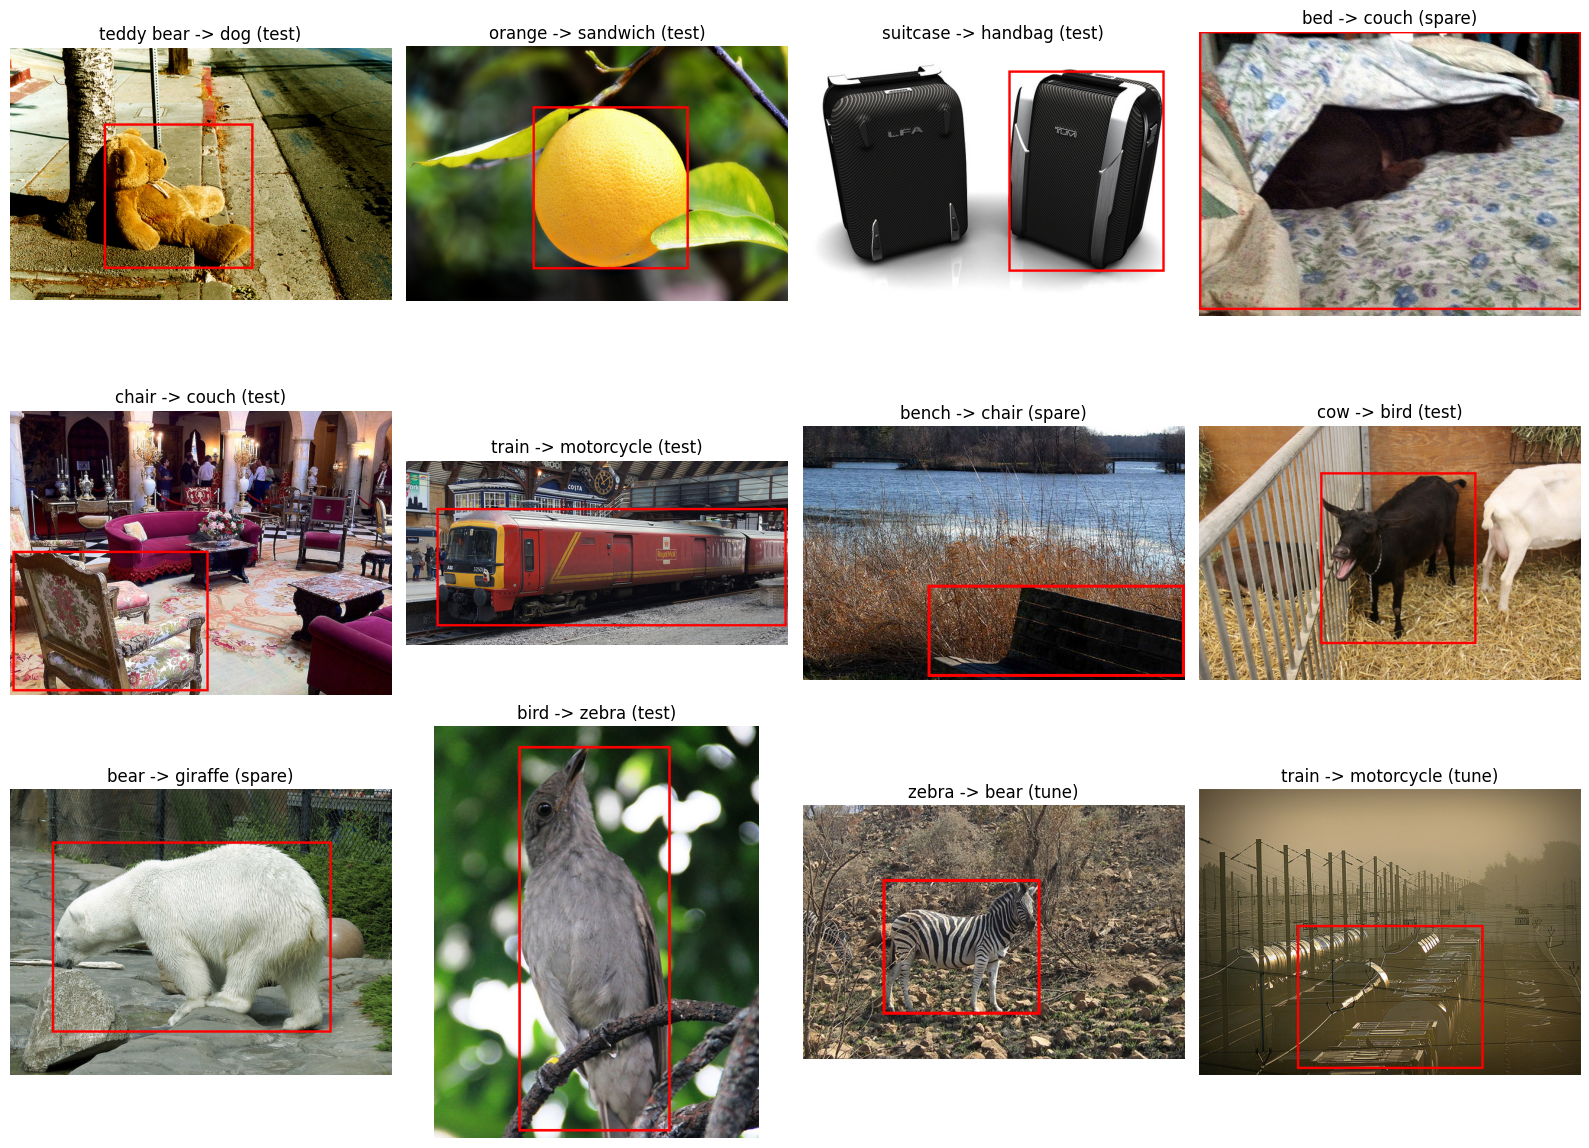

In [13]:
import io, urllib.request
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

sample = atk.sample(12, random_state=1)
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
for ax, (_, r) in zip(axes.flat, sample.iterrows()):
    url = 'http://images.cocodataset.org/val2017/' + r['file_name']
    im = Image.open(io.BytesIO(urllib.request.urlopen(url).read())).convert('RGB')
    ImageDraw.Draw(im).rectangle([r['box_x'], r['box_y'], r['box_x'] + r['box_w'], r['box_y'] + r['box_h']], outline='red', width=4)
    ax.imshow(im)
    ax.set_title(f"{r['category']} -> {r['on_topic_target']} ({r['split']})")
    ax.axis('off')
plt.tight_layout()
plt.show()

## Summary
If every check above printed OK, tickets A1 and A2 are verified. The next ticket (A3) renders text onto these photos.

In [ ]:
print(atk.groupby('split')['supercategory'].value_counts().unstack(fill_value=0))